# 04 — Model Building & Evaluation

Trains Naive Bayes, Logistic Regression, LinearSVC, Random Forest and Gradient Boosting on the features from notebook 03. Hyperparameters are tuned with cross-validated search on a stratified subsample, each tuned model is refit on the full training split and scored on a stratified validation split, and the final numbers are reported on the held-out AG News test set. Results are saved to `reports/results.json` for notebook 05.

In [1]:
import os, json, time, warnings
import numpy as np, scipy.sparse as sp, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
warnings.filterwarnings('ignore')
SEED = 42
os.makedirs('reports', exist_ok=True)
le = joblib.load('models/label_encoder.joblib'); classes = list(le.classes_)
y_all = np.load('models/features/y_train.npy'); y_test = np.load('models/features/y_test.npy')
Xt_all = sp.load_npz('models/features/tfidf_train.npz'); Xt_test = sp.load_npz('models/features/tfidf_test.npz')
Xb_all = sp.load_npz('models/features/bow_train.npz'); Xb_test = sp.load_npz('models/features/bow_test.npz')
idx_tr, idx_val = train_test_split(np.arange(len(y_all)), test_size=0.1, stratify=y_all, random_state=SEED)
y_tr, y_val = y_all[idx_tr], y_all[idx_val]
Xt_tr, Xt_val = Xt_all[idx_tr], Xt_all[idx_val]; Xb_tr, Xb_val = Xb_all[idx_tr], Xb_all[idx_val]
# stratified 30k subsample for hyperparameter search
idx_sub, _ = train_test_split(np.arange(len(y_tr)), train_size=30000, stratify=y_tr, random_state=SEED)
print(Xt_tr.shape, Xt_val.shape, Xt_test.shape, 'tuning subsample:', len(idx_sub))

(108000, 100000) (12000, 100000) (7600, 100000) tuning subsample: 30000


## Evaluation helper

In [2]:
results = {}
def evaluate(name, model, Xtr, Xval, Xte, features, best_params=None, cv_score=None):
    t0 = time.time(); model.fit(Xtr, y_tr); fit_s = time.time() - t0
    out = {'features': features, 'best_params': best_params, 'cv_f1_macro': cv_score, 'fit_seconds': round(fit_s, 1)}
    pv = model.predict(Xval); out['val_accuracy'] = accuracy_score(y_val, pv)
    t0 = time.time(); pt = model.predict(Xte); out['predict_ms_per_1000'] = round((time.time() - t0) / len(y_test) * 1e6, 1)
    p, r, f, _ = precision_recall_fscore_support(y_test, pt, average='weighted')
    pm, rm, fm, _ = precision_recall_fscore_support(y_test, pt, average='macro')
    out.update(test_accuracy=accuracy_score(y_test, pt), precision=p, recall=r, f1=f, f1_macro=fm)
    out['per_class'] = classification_report(y_test, pt, target_names=classes, output_dict=True)
    out['confusion_matrix'] = confusion_matrix(y_test, pt).tolist()
    results[name] = out
    joblib.dump(model, f'models/{name}.joblib')
    print(f"{name:28s} val_acc={out['val_accuracy']:.4f} test_acc={out['test_accuracy']:.4f} F1={f:.4f} fit={fit_s:.0f}s")
    return model
def search(est, grid, X, kind=GridSearchCV, **kw):
    s = kind(est, grid, cv=3, scoring='f1_macro', n_jobs=2, **kw).fit(X[idx_sub], y_tr[idx_sub])
    print(s.best_params_, round(s.best_score_, 4)); return s.best_estimator_.get_params(), s.best_params_, s.best_score_

## 1. Multinomial Naive Bayes (TF-IDF, and BoW for comparison)

In [3]:
_, bp, cv = search(MultinomialNB(), {'alpha': [0.03, 0.1, 0.3, 1.0]}, Xt_tr)
evaluate('naive_bayes', MultinomialNB(**bp), Xt_tr, Xt_val, Xt_test, 'TF-IDF', bp, cv)
_, bp, cv = search(MultinomialNB(), {'alpha': [0.03, 0.1, 0.3, 1.0]}, Xb_tr)
evaluate('naive_bayes_bow', MultinomialNB(**bp), Xb_tr, Xb_val, Xb_test, 'BoW', bp, cv)

{'alpha': 0.1} 0.9043
naive_bayes                  val_acc=0.9175 test_acc=0.9076 F1=0.9074 fit=0s


{'alpha': 0.3} 0.8978
naive_bayes_bow              val_acc=0.9112 test_acc=0.9018 F1=0.9016 fit=0s


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",0.3
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](4,)","[27000.,27000.,27000.,27000.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](4,)","[-1.39,-1.39,-1.39,-1.39]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[0,1,2,3]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](4, 25393)","[[18., 6., 0.,..., 0., 0., 2.], [ 1., 1., 3.,..., 0., 0., 0.], [37., 2., 0.,..., 9., 5., 1.], [ 1., 0., 0.,..., 0., 0., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](4, 25393)","[[-10.45,-11.52,-14.56,...,-14.56,-14.56,-12.53], [-13.07,-13.07,-12.13,...,-14.53,-14.53,-14.53], [ -9.68,-12.47,-14.51,...,-11.07,-11.63,-13.04], [-13.12,-14.59,-14.59,...,-14.59,-14.59,-14.59]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,25393


## 2. Logistic Regression (TF-IDF, and BoW for comparison)

In [4]:
_, bp, cv = search(LogisticRegression(max_iter=300), {'C': [1, 5, 20]}, Xt_tr)
evaluate('logistic_regression', LogisticRegression(max_iter=300, **bp), Xt_tr, Xt_val, Xt_test, 'TF-IDF', bp, cv)
evaluate('logistic_regression_bow', LogisticRegression(max_iter=300, C=1.0), Xb_tr, Xb_val, Xb_test, 'BoW', {'C': 1.0}, None)

{'C': 5} 0.9055


logistic_regression          val_acc=0.9257 test_acc=0.9200 F1=0.9199 fit=13s


logistic_regression_bow      val_acc=0.9108 test_acc=0.9024 F1=0.9023 fit=3s


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",300
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

## 3. Linear SVM (LinearSVC)

In [5]:
_, bp, cv = search(LinearSVC(), {'C': [0.1, 0.3, 1.0]}, Xt_tr)
evaluate('linear_svc', LinearSVC(**bp), Xt_tr, Xt_val, Xt_test, 'TF-IDF', bp, cv)

{'C': 0.3} 0.9075


linear_svc                   val_acc=0.9292 test_acc=0.9236 F1=0.9234 fit=2s


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.3
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

## 4. Random Forest
Trees on 100k sparse features are slow, so the 20,000 most class-informative features (chi-squared) are selected first.

In [6]:
rf_pipe = make_pipeline(SelectKBest(chi2, k=20000), RandomForestClassifier(n_jobs=2, random_state=SEED))
grid = {'randomforestclassifier__n_estimators': [150], 'randomforestclassifier__max_depth': [None, 80], 'randomforestclassifier__min_samples_leaf': [1, 2]}
_, bp, cv = search(rf_pipe, grid, Xt_tr, kind=RandomizedSearchCV, n_iter=3, random_state=SEED) if False else search(rf_pipe, grid, Xt_tr)
evaluate('random_forest', make_pipeline(SelectKBest(chi2, k=20000), RandomForestClassifier(n_jobs=2, random_state=SEED, **{k.split('__')[1]: v for k, v in bp.items()})), Xt_tr, Xt_val, Xt_test, 'TF-IDF (chi2 top 20k)', {k.split('__')[1]: v for k, v in bp.items()}, cv)

{'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 150} 0.868


random_forest                val_acc=0.9030 test_acc=0.8989 F1=0.8986 fit=220s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('selectkbest', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,100000
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function chi...x7f044b8987c0>
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",20000
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,100000


## 5. Gradient Boosting
`HistGradientBoostingClassifier` needs dense input, so TF-IDF is first reduced with TruncatedSVD (LSA, 200 components).

In [7]:
gb_pipe = make_pipeline(TruncatedSVD(200, random_state=SEED), HistGradientBoostingClassifier(random_state=SEED))
grid = {'histgradientboostingclassifier__learning_rate': [0.1, 0.2], 'histgradientboostingclassifier__max_iter': [150]}
_, bp, cv = search(gb_pipe, grid, Xt_tr)
bp2 = {k.split('__')[1]: v for k, v in bp.items()}
evaluate('gradient_boosting', make_pipeline(TruncatedSVD(200, random_state=SEED), HistGradientBoostingClassifier(random_state=SEED, **bp2)), Xt_tr, Xt_val, Xt_test, 'TF-IDF + SVD(200)', bp2, cv)

{'histgradientboostingclassifier__learning_rate': 0.1, 'histgradientboostingclassifier__max_iter': 150} 0.8744


gradient_boosting            val_acc=0.8967 test_acc=0.8904 F1=0.8901 fit=50s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('truncatedsvd', ...), ('histgradientboostingclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,100000
,"n_components n_components: int, default=2Desired dimensionality of output data.If algorithm='arpack', must be strictly less than the number of features.If algorithm='randomized', must be less than or equal to the number of features.The default value is useful for visualisation. For LSA, a value of100 is recommended.",200
,"random_state random_state: int, RandomState instance or None, default=NoneUsed during randomized svd. Pass an int for reproducible results acrossmultiple function calls.See :term:`Glossary <random_state>`.",42
,"algorithm algorithm: {'arpack', 'randomized'}, default='randomized'SVD solver to use. Either ""arpack"" for the ARPACK wrapper in SciPy(scipy.sparse.linalg.svds), or ""randomized"" for the randomizedalgorithm due to Halko (2009).",'randomized'
,"n_iter n_iter: int, default=5Number of iterations for randomized SVD solver. Not used by ARPACK. Thedefault is larger than the default in:func:`~sklearn.utils.extmath.randomized_svd` to handle sparsematrices that may have large slowly decaying spectrum.",5


## Save results & quick look

In [8]:
json.dump(results, open('reports/results.json', 'w'), indent=2)
import pandas as pd
pd.DataFrame({k: {m: v[m] for m in ['features','val_accuracy','test_accuracy','precision','recall','f1','f1_macro','fit_seconds','predict_ms_per_1000']} for k, v in results.items()}).T.round(4)

,features,val_accuracy,test_accuracy,precision,recall,f1,f1_macro,fit_seconds,predict_ms_per_1000
naive_bayes,TF-IDF,0.9175,0.907632,0.907555,0.907632,0.907415,0.907415,0.0,0.3
naive_bayes_bow,BoW,0.911167,0.901842,0.901534,0.901842,0.901598,0.901598,0.0,0.2
logistic_regression,TF-IDF,0.925667,0.92,0.919857,0.92,0.91987,0.91987,12.8,0.2
logistic_regression_bow,BoW,0.910833,0.902368,0.902324,0.902368,0.902303,0.902303,3.2,0.2
linear_svc,TF-IDF,0.929167,0.923553,0.923503,0.923553,0.923391,0.923391,2.4,0.2
random_forest,TF-IDF (chi2 top 20k),0.903,0.898947,0.898687,0.898947,0.898595,0.898595,219.6,56.1
gradient_boosting,TF-IDF + SVD(200),0.896667,0.890395,0.890035,0.890395,0.890109,0.890109,49.9,34.5


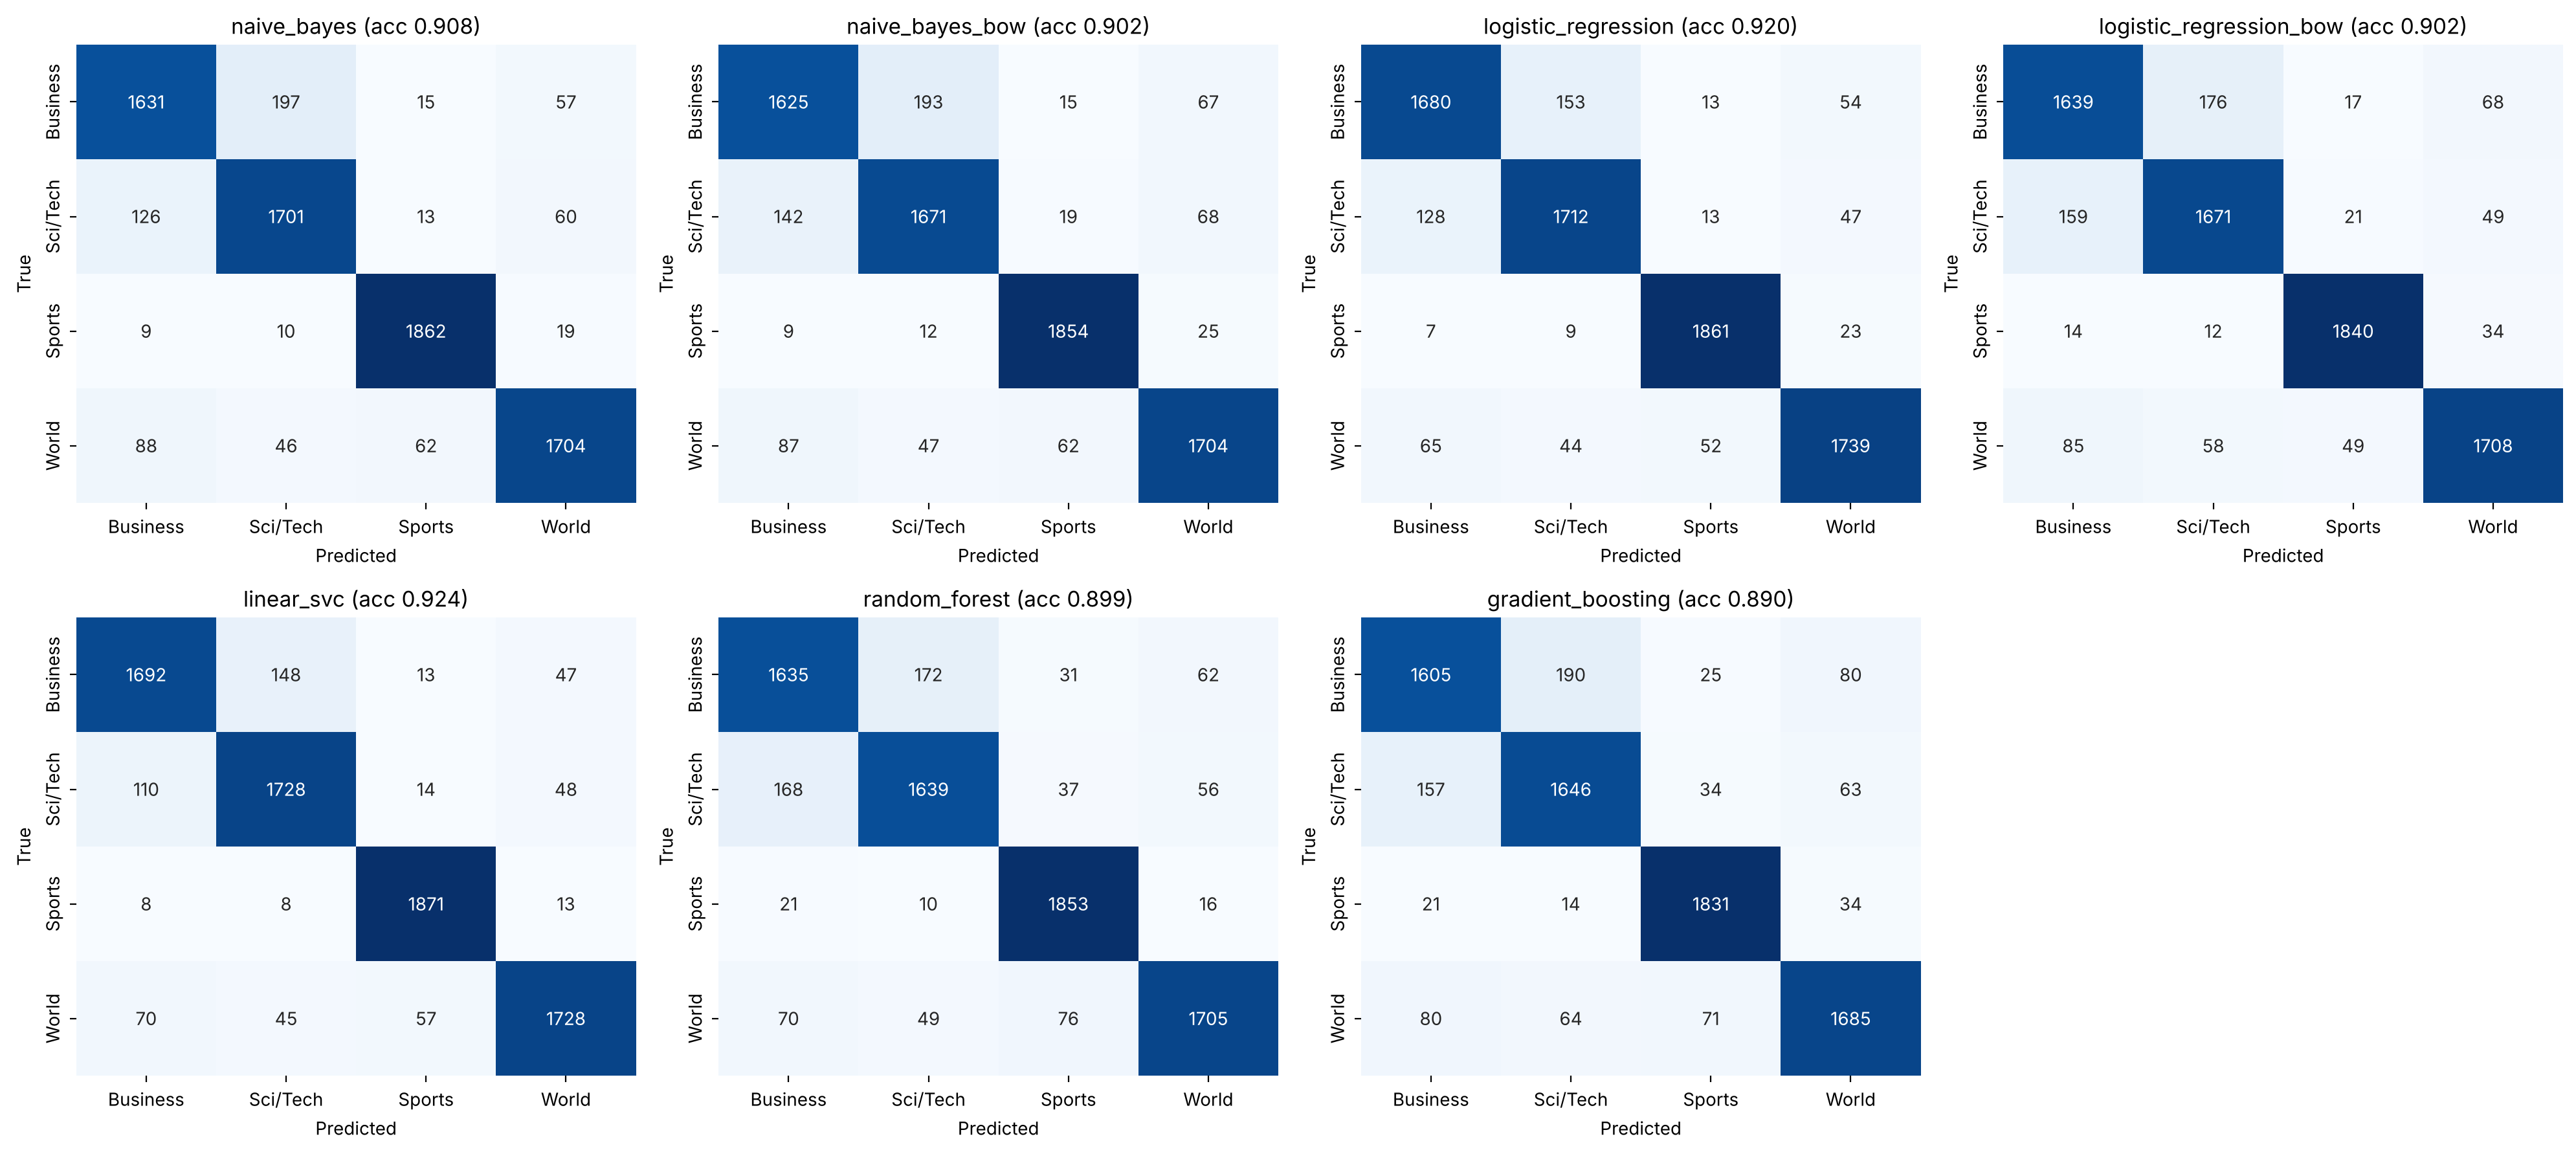

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9)); 
for ax, (name, r) in zip(axes.ravel(), results.items()):
    sns.heatmap(r['confusion_matrix'], annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(f"{name} (acc {r['test_accuracy']:.3f})"); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
for ax in axes.ravel()[len(results):]: ax.axis('off')
plt.tight_layout(); plt.savefig('reports/confusion_matrices.png', dpi=110); plt.show()